# Análise de métricas de classificação: Titanic

Este notebook treina um modelo para prever a sobrevivência de passageiros do Titanic. O fluxo inclui análise inicial, tratamento dos dados, transformação de variáveis categóricas, treinamento e avaliação.

**Fonte da base:** [Seaborn Titanic dataset](https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv).

## 1. Importação e carregamento da base

A base `titanic.csv` está armazenada localmente para tornar a análise reproduzível.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

dados = pd.read_csv("titanic.csv")
dados.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Conhecendo os dados

A variável-alvo é `survived`: 0 representa não sobrevivente e 1 representa sobrevivente.

In [2]:
print(f"Linhas: {dados.shape[0]} | Colunas: {dados.shape[1]}")
display(dados.dtypes.to_frame("tipo"))
display(dados.isna().sum().sort_values(ascending=False).to_frame("valores_ausentes"))
display(dados["survived"].value_counts(normalize=True).rename("proporcao"))

Linhas: 891 | Colunas: 15


,tipo
survived,int64
pclass,int64
sex,str
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,str
class,str
who,str


,valores_ausentes
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


survived
0    0.616162
1    0.383838
Name: proporcao, dtype: float64

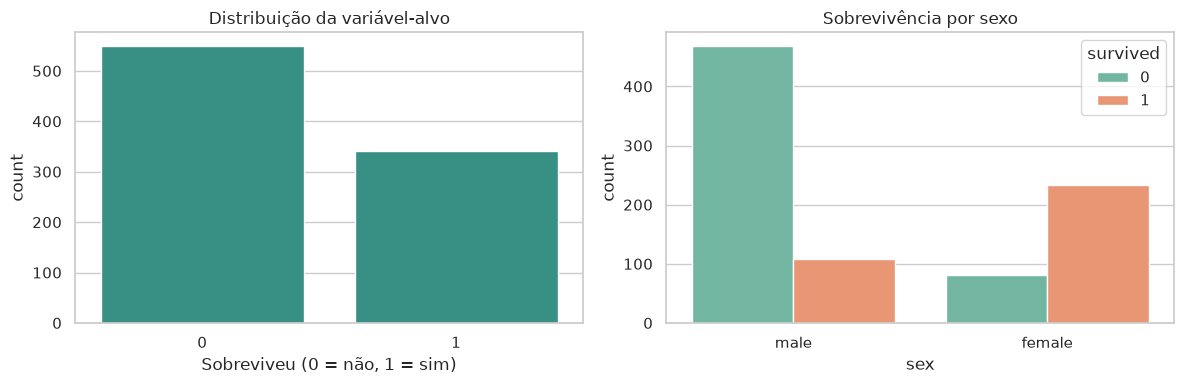

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=dados, x="survived", ax=axes[0], color="#2a9d8f")
axes[0].set_title("Distribuição da variável-alvo")
axes[0].set_xlabel("Sobreviveu (0 = não, 1 = sim)")
sns.countplot(data=dados, x="sex", hue="survived", ax=axes[1], palette="Set2")
axes[1].set_title("Sobrevivência por sexo")
plt.tight_layout()
plt.show()

## 3. Preparação e transformação

Serão usadas as variáveis `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare` e `embarked`. A coluna `deck` tem muitos valores ausentes e será excluída. O pipeline preenche valores ausentes, padroniza variáveis numéricas e transforma categorias em colunas binárias com one-hot encoding.

In [4]:
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
target = "survived"

X = dados[features]
y = dados[target]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

features_numericas = ["pclass", "age", "sibsp", "parch", "fare"]
features_categoricas = ["sex", "embarked"]

transformador_numerico = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("padronizador", StandardScaler()),
])
transformador_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(handle_unknown="ignore")),
])

preprocessador = ColumnTransformer([
    ("numericas", transformador_numerico, features_numericas),
    ("categoricas", transformador_categorico, features_categoricas),
])

## 4. Treinamento e previsões

A regressão logística foi escolhida por ser um modelo de classificação simples e interpretável. O pipeline garante que o pré-processamento seja aprendido apenas com os dados de treinamento.

In [5]:
modelo = Pipeline([
    ("preprocessamento", preprocessador),
    ("classificador", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)

print(f"Amostras de treino: {len(X_treino)}")
print(f"Amostras de teste: {len(X_teste)}")

Amostras de treino: 712
Amostras de teste: 179


## 5. Métricas de avaliação

A matriz de confusão permite observar os acertos e erros por classe. Precisão responde quantos passageiros classificados como sobreviventes realmente sobreviveram; recall responde quantos sobreviventes reais foram identificados pelo modelo.

In [6]:
acuracia = accuracy_score(y_teste, previsoes)
precisao = precision_score(y_teste, previsoes)
recall = recall_score(y_teste, previsoes)
f1 = f1_score(y_teste, previsoes)

metricas = pd.DataFrame({
    "Métrica": ["Acurácia", "Precisão", "Recall", "F1-score"],
    "Valor": [acuracia, precisao, recall, f1],
})
display(metricas.style.format({"Valor": "{:.2%}"}))
print(classification_report(y_teste, previsoes, target_names=["Não sobreviveu", "Sobreviveu"]))

,Métrica,Valor
0,Acurácia,80.45%
1,Precisão,79.31%
2,Recall,66.67%
3,F1-score,72.44%


                precision    recall  f1-score   support

Não sobreviveu       0.81      0.89      0.85       110
    Sobreviveu       0.79      0.67      0.72        69

      accuracy                           0.80       179
     macro avg       0.80      0.78      0.79       179
  weighted avg       0.80      0.80      0.80       179



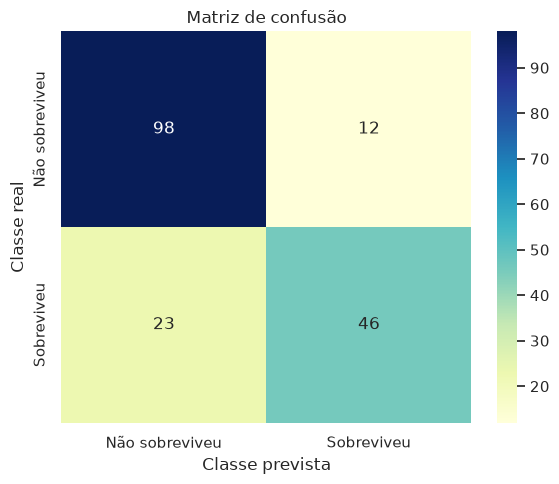

Verdadeiros negativos: 98
Falsos positivos: 12
Falsos negativos: 23
Verdadeiros positivos: 46


In [7]:
matriz = confusion_matrix(y_teste, previsoes)
plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=["Não sobreviveu", "Sobreviveu"],
    yticklabels=["Não sobreviveu", "Sobreviveu"],
)
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de confusão")
plt.tight_layout()
plt.show()

print(f"Verdadeiros negativos: {matriz[0, 0]}")
print(f"Falsos positivos: {matriz[0, 1]}")
print(f"Falsos negativos: {matriz[1, 0]}")
print(f"Verdadeiros positivos: {matriz[1, 1]}")

## 6. Avaliação final

O modelo deve ser avaliado em conjunto, e não apenas pela acurácia. A precisão mostra a confiabilidade das previsões positivas, enquanto o recall indica a capacidade de encontrar os passageiros que realmente sobreviveram. O F1-score resume o equilíbrio entre precisão e recall.

Os valores exibidos acima devem ser usados na apresentação. Como a divisão dos dados é fixa com `random_state=42`, os resultados podem ser reproduzidos. As principais limitações são a simplicidade do modelo, a quantidade de variáveis utilizadas e o fato de a base representar um evento histórico específico.